# Automated Malaria Cell Detection — Phase 3: testing our hypotheses (A1–A3)
## Does the 97–98 % hold on patients the model has never seen, and does YUV stain normalisation help?

**Team:** J Amathziah (230139): Kaggle runs, repo · C Murali Madhav (230115): code (notebook, scripts) · Ravi Yadav (230131): slides · Pugazhendhi J (230066): report
**Base paper:** G. Marques, A. Ferreras, I. de la Torre-Díez, "An ensemble-based approach for automated medical diagnosis of malaria using EfficientNet," *Multimedia Tools and Applications*, 81, 28061–28078, 2022.
**Baseline (A0):** `Phase2_A0_10fold_PaperExact.ipynb`, the paper's own recipe on all 10 folds, within 1 pp of the paper on every metric.

### The hypotheses, as we stated them before running anything (Phase 2 deck, slides 28–29)
* **H1 · validation.** Split by patient instead of by image. *Expect:* accuracy and MCC fall below the image-split baseline, and fold-to-fold spread widens. *Because:* cells from one patient share stain, lighting and the patient's blood, so a random image split lets the model recognise the patient instead of the parasite.
* **H2 · preprocessing.** RGB → YUV → histogram-equalise Y → RGB before EfficientNet-B0 (Umer *et al.* 2020), patient split kept. *Expect:* higher recall and MCC than H1 on unseen patients; little change on the random split.
* **Falsifiable:** if H2's gain over H1 is smaller than the fold-to-fold SD, we reject H2. If grouped and random splits score the same, H1 is rejected.

| ID | Split | Preprocessing | What it answers |
|---|---|---|---|
| A0 | image (paper) | none | baseline (done, Phase 2) |
| A1 | **patient** | none | H1: how much does patient leakage inflate the scores (A0 vs A1)? |
| A2 | **patient** | **YUV + hist-eq** | H2: does stain normalisation help on unseen patients (A2 vs A1)? |
| A3 | image (paper) | **YUV + hist-eq** | control: does YUV change anything when patients are shared (A3 vs A0)? |

**One change at a time.** Everything else is A0's recipe, unchanged: noisy-student EfficientNet-B0 with the paper's dense head, label smoothing 0.1, Adam 1e-4, ReduceLROnPlateau, 33 epochs × batch 16, best-val_loss checkpoint, the paper's albumentations pipeline, the same seeds per fold, the same 10-model averaging ensemble. A3 even reuses A0's exact split (same fingerprint), so A3 vs A0 compares the same cells, fold by fold; A2 vs A1 likewise share their patient split.

**Decided before the runs** (full analysis plan: `docs/phase3_analysis_plan.md`, committed before the runs):
* *Patient key* = the file name's leading C-number. It matches NIH's own patient-to-cell mapping for all 27,558 cells (200 patients; NIH lists patient C47 under two keys, one per microscope, which the C-number merges).
* *Patient split*: `StratifiedGroupKFold(5)` gives five candidate hold-out sets of ~20 %; we take the one closest to 20 % of the cells and 50 % parasitized (a rule on labels only). Then `StratifiedGroupKFold(10, random_state=50)` on the rest. The split is saved in `results/A1_slide_split/split.csv` so every machine trains on exactly the same one.
* *Statistics*: patients are the unit (all intervals resample whole patients); primary protocol = clean (un-augmented) evaluation, primary metric = MCC; paired contrasts use the Nadeau–Bengio corrected t-test over folds and a paired patient bootstrap of the ensemble; Holm correction over the three contrasts.

## 1 · Parameters

In [1]:
EXPERIMENTS = ["A1", "A2", "A3"]   # any of A1-A3 (A0 is the Phase 2 run; its folds are read for the comparison)
FOLDS_TO_TRAIN = []                # [k] on a pod, list(range(10)) on one machine, empty for tables only
AGGREGATE = True                   # build each experiment's tables once all 10 of its folds are in
DATA_DIR = "../outputs/data"       # NIH cell_images (downloaded if missing; git-ignored)
CACHE_DIR = "../outputs"           # decoded image caches, 4.1 GB each, one per preprocessing (git-ignored)
RESULTS_ROOT = "../results"        # results/<experiment folder>/: split.csv, folds/, tables, figures
FOLDS_ROOT = None                  # where new folds go (None: RESULTS_ROOT/<folder>/folds; pods: /workspace/out)
N_WORKERS = None                   # augmentation processes (None: the CPUs the container allows, minus 2)
XLA = True                         # XLA-compile the training step (speed only)
SMOKE = False                      # quick pipeline test: 5 % of the images, 2 epochs of 20 steps, live split
N_BOOT = 10_000                    # patient-bootstrap resamples for the hypothesis tests

In [2]:
# Parameters
N_BOOT = 10000


In [3]:
%matplotlib inline
import json, os, sys, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "1")
os.environ.setdefault("TF_GPU_THREAD_MODE", "gpu_private")  # dedicated host threads launch the GPU kernels
import warnings; warnings.filterwarnings("ignore", category=DeprecationWarning)

SRC = next(p for p in ["../src", "src", "/workspace/repo/src"] if os.path.exists(os.path.join(p, "marques2022_exact.py")))
sys.path.insert(0, os.path.abspath(SRC))
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.metrics import classification_report
import marques2022_exact as mx

TRAINING = len(FOLDS_TO_TRAIN) > 0
EXPECTED = json.load(open(os.path.join(RESULTS_ROOT, "ablation_splits.json")))  # committed split fingerprints
folder = lambda exp: os.path.join(RESULTS_ROOT, mx.EXPERIMENTS[exp]["folder"])
folds_dir = lambda exp: (os.path.join(FOLDS_ROOT, mx.EXPERIMENTS[exp]["folder"]) if FOLDS_ROOT
                         else os.path.join(folder(exp), "folds"))
display(pd.DataFrame(mx.EXPERIMENTS).T[["split", "preprocess", "question"]])
print("Recipe (A0's, from the paper's code):", json.dumps(mx.PAPER))
print("Experiments here:", EXPERIMENTS, "| folds to train:", FOLDS_TO_TRAIN or "none (tables only)")

,split,preprocess,question
A0,image,none,Baseline: the paper's protocol
A1,patient,none,H1: how much does patient leakage inflate the ...
A2,patient,yuv,H2: does YUV stain normalisation help on unsee...
A3,image,yuv,Control: does YUV change anything when patient...


Recipe (A0's, from the paper's code): {"SEED": 1234, "KFOLD": 10, "KFOLD_SEED": 50, "EPOCHS": 33, "BATCH_SIZE": 16, "IMG_SIZE": 224, "LR": 0.0001, "LR_FACTOR": 0.5, "PATIENCE": 6, "MIN_LR": 1e-06, "LABEL_SMOOTHING": 0.1, "VAL_FRACTION": 0.2, "WEIGHTS": "noisy-student", "DENSE": [128, 64, 32], "DROPOUT": 0.3}
Experiments here: ['A1', 'A2', 'A3'] | folds to train: none (tables only)


## 2 · Data and the two splits
NIH malaria cell images: 27,558 cells from 200 patients (150 infected, 50 healthy). Each file name starts with the patient's C-number, e.g. `C33P1thinF_IMG_20150619_114756a_cell_179.png` → patient C33. Infected patients also contribute **uninfected** cells (10,364 of the 13,779), so under the paper's random image split almost every patient has cells on both sides.

* **Image split (A0, A3):** the paper's `train_test_split(test_size=0.2)` + `StratifiedKFold(10)`, rebuilt exactly as in A0 (its fingerprint is checked below).
* **Patient split (A1, A2):** the same proportions, but every patient's cells go to one side only. Patients differ a lot (65–702 cells; 1–90 % parasitized), so the folds' class mix varies more than under the image split; MCC and balanced accuracy are less sensitive to that than accuracy.

In [4]:
def describe(learn, val, folds):
    pts = lambda d: d["file"].map(mx.patient_id).nunique()
    share = lambda d: f"{100 * (d['label'] == 'Parasitized').mean():.1f} %"
    rows = [dict(part="learning set (10-fold CV)", cells=len(learn), patients=pts(learn), parasitized=share(learn)),
            dict(part="hold-out set", cells=len(val), patients=pts(val), parasitized=share(val))]
    rows += [dict(part=f"fold {k}: test part", cells=len(te), patients=pts(learn.iloc[te]), parasitized=share(learn.iloc[te]))
             for k, (_, te) in enumerate(folds)]
    return pd.DataFrame(rows).set_index("part")

if TRAINING:
    root = mx.find_or_download(DATA_DIR)
    df = mx.index_dataset(root)
    if SMOKE:  # like the paper's QUICK_AND_DIRTY switch; the committed split needs all images, so split live
        df = mx.build_index(df.sample(frac=0.05, random_state=mx.PAPER["SEED"])[["file", "label"]].values, root)
    print(f"Images: {len(df):,}", df["label"].value_counts().to_dict())
    splits = {}
    for exp in EXPERIMENTS:
        kind = mx.EXPERIMENTS[exp]["split"]
        if kind == "patient" and not SMOKE:
            splits[exp] = mx.load_split(os.path.join(folder(exp), "split.csv"), df)
        else:
            splits[exp] = mx.make_split(df, kind)
        if kind == "patient":
            mx.check_no_shared_patients(*splits[exp])
        fp = mx.split_fingerprint(*splits[exp])
        print(f"{exp}: {kind} split, fingerprint {fp}" + ("" if SMOKE else f" (committed: {EXPECTED[kind]})"))
        assert SMOKE or fp == EXPECTED[kind], f"{exp} would not train on the committed {kind} split"
    for kind in dict.fromkeys(mx.EXPERIMENTS[e]["split"] for e in EXPERIMENTS):
        exp = next(e for e in EXPERIMENTS if mx.EXPERIMENTS[e]["split"] == kind)
        print(f"\n{kind} split"); display(describe(*splits[exp]))
else:
    s = pd.read_csv(os.path.join(folder("A1"), "split.csv"))
    learn, val = s[s.role == "learn"].reset_index(drop=True), s[s.role == "holdout"].reset_index(drop=True)
    folds = [(np.flatnonzero(learn.fold != k), np.flatnonzero(learn.fold == k)) for k in range(learn.fold.max() + 1)]
    print("Patient split (A1, A2), from results/A1_slide_split/split.csv:"); display(describe(learn, val, folds))

Patient split (A1, A2), from results/A1_slide_split/split.csv:


,cells,patients,parasitized
part,,,
learning set (10-fold CV),22008,160,49.8 %
hold-out set,5550,40,50.7 %
fold 0: test part,3245,16,66.6 %
fold 1: test part,1661,16,29.8 %
fold 2: test part,2887,15,64.1 %
fold 3: test part,2194,16,49.3 %
fold 4: test part,1892,16,41.5 %
fold 5: test part,2005,17,42.4 %
fold 6: test part,3011,16,63.8 %


## 3 · The YUV preprocessing (H2)
Umer *et al.* (2020) convert each cell to YUV, equalise the brightness (Y) histogram, and convert back to RGB, so the network sees cells with the same brightness spread whatever the slide's stain and lighting. We do exactly that with OpenCV (`COLOR_BGR2YUV` → `equalizeHist` on Y → `COLOR_YUV2BGR`) at each image's native size, then apply A0's resize and augmentation unchanged. Colour (U, V) is left as it is. The pure-black background stays black (`equalizeHist` maps the lowest grey level to 0). Two deviations from Umer: no 120 × 120 resize (we keep 224, as A0) and no edge kernel (the paper does not specify it).

The equalisation is strong: a cell's narrow brightness range is stretched over 0–255, which also amplifies texture and noise (bottom row). Whether that helps or hurts on unseen patients is exactly what A2 vs A1 measures, and A3 vs A0 shows its effect when patients are shared.

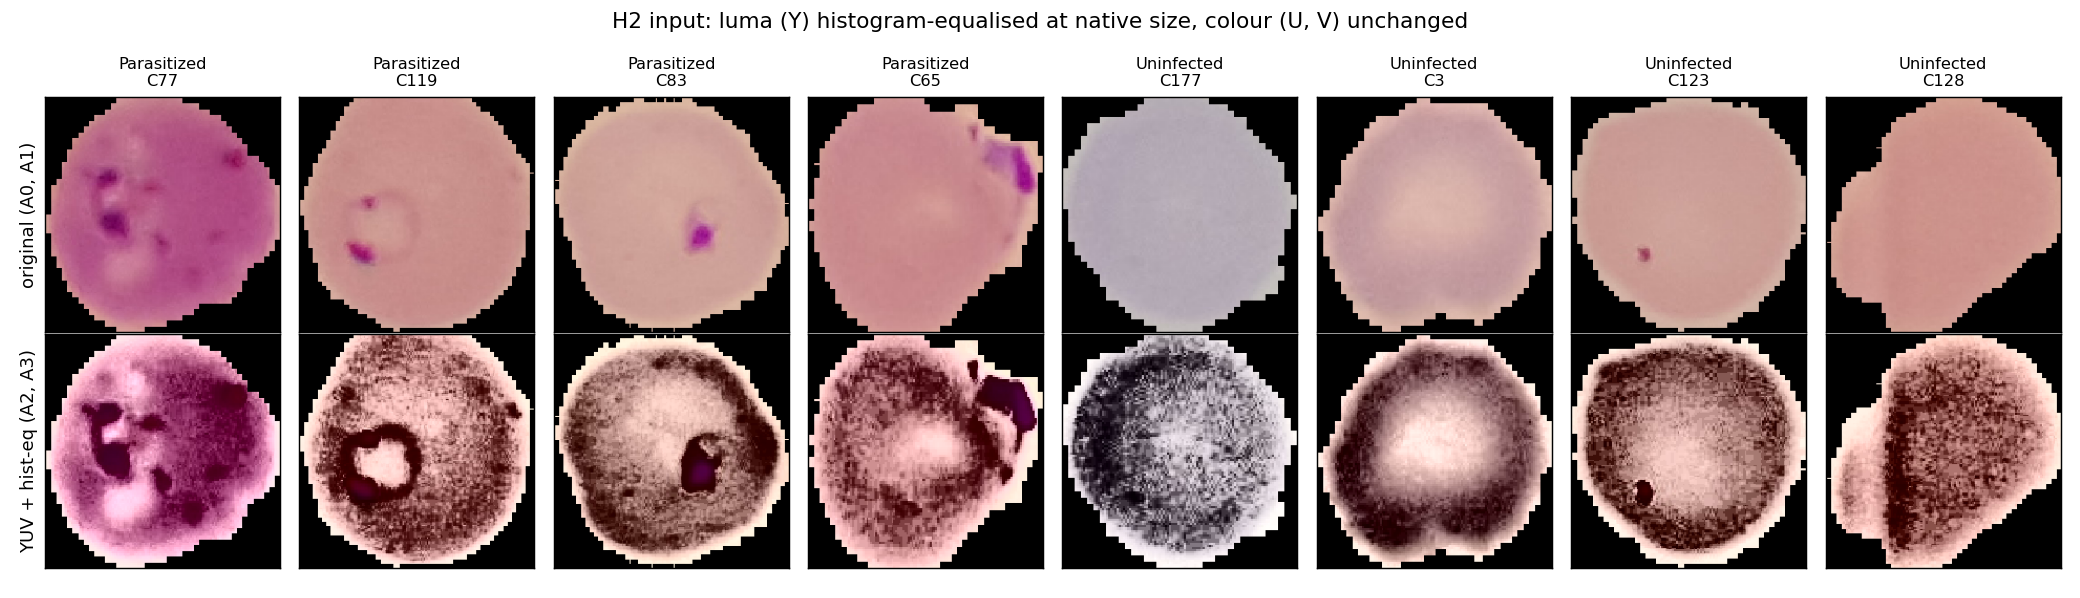

In [5]:
fig_path = os.path.join(folder("A2"), "yuv_examples.png")
if os.path.exists(fig_path):
    display(Image(fig_path))

## 4 · Train the folds
Exactly A0's training loop (`mx.train_fold`), now with `experiment=` set: 33 epochs × ~1,200 steps of 16 images, validation on the fold's test part after every epoch, ReduceLROnPlateau, the best-val_loss checkpoint reloaded, then predictions on the test part and on the hold-out set, both clean and augmented. Each preprocessing gets its own image cache (`cell_images_224_none.npy`, `cell_images_224_yuv.npy`); a small `.json` next to each records how it was built, and `train_fold` refuses a cache that doesn't match the experiment.

On RunPod, each pod trains fold *k* of A1, A2 and A3 one after another (`src/runpod_10fold.py --experiments A1,A2,A3`), so the 10 pods finish all 30 models in about an hour.

In [6]:
def print_like_the_paper(res, exp):
    npz = np.load(os.path.join(folds_dir(exp), f"fold_{res['fold']}", f"fold_{res['fold']}_predictions.npz"))
    for name, title in [("test_clean", "Predicting... (CV test part, clean)"), ("val_clean", "Validating... (hold-out set, clean)"),
                        ("val_aug", "Validating... (hold-out set, augmented = paper protocol)")]:
        y_true = npz["test_true" if name.startswith("test") else "val_true"]
        pred = res["probs"][name].argmax(1)
        print(title, f"\nAccuracy {np.mean(pred == y_true):.6f}")
        print(classification_report(y_true, pred, labels=[0, 1], target_names=mx.TIPOS, digits=6, zero_division=0))

if TRAINING:
    workers = N_WORKERS or max(1, mx.available_cpus() - 2)
    smoke = dict(epochs=2, max_steps_per_epoch=20) if SMOKE else {}
    for exp in EXPERIMENTS:
        prep = mx.EXPERIMENTS[exp]["preprocess"]
        cache = os.path.join(CACHE_DIR, f"cell_images_224_{prep}{'_smoke' if SMOKE else ''}.npy")
        if not os.path.exists(cache + ".json"):  # the .json is written last, so a half-built cache is rebuilt
            t0 = time.time()
            mx.build_image_cache(list(df["path"]), cache, workers=mx.available_cpus(), preprocess=prep)
            print(f"Image cache ({prep}) built in {time.time() - t0:.0f} s")
        learn, val, folds = splits[exp]
        with mx.AugmentPool(workers, cache) as pool:
            for k in FOLDS_TO_TRAIN:
                print("*" * 50, f"\n** {exp} · {mx.EXPERIMENTS[exp]['split']} split · preprocess={prep} · fold {k}"
                      f"   ({workers} augmentation workers)")
                print(f"Found {len(folds[k][0])} / {len(folds[k][1])} / {len(val)} images (train / test / hold-out)")
                t0 = time.time()
                res = mx.train_fold(k, learn=learn, val=val, folds=folds, pool=pool, out_dir=folds_dir(exp), xla=XLA,
                                    experiment=exp, **smoke)
                print_like_the_paper(res, exp)
                print(f"Best epoch {res['best_epoch']} of {res['epochs']} · training {res['train_seconds'] / 60:.1f} min "
                      f"(median epoch {np.median(res['epoch_seconds']):.0f} s) · End of {exp} fold {k} - Elapsed Time: "
                      f"{time.strftime('%H:%M:%S', time.gmtime(time.time() - t0))}")

## 5 · Results of each experiment
Built from the saved outputs of all 10 folds of each experiment (`mx.aggregate` re-checks that no patient is on both sides of any fold or of the hold-out split). Tables use **clean** evaluation; the ensemble is also reported under the paper's augmented protocol. Files per experiment: `results/<folder>/<ID>_summary.json`, per-fold CSVs, and `<ID>_curves_cm_roc.png`.

In [7]:
done = {exp: [k for k in range(10) if os.path.exists(os.path.join(folds_dir(exp), f"fold_{k}", f"fold_{k}.json"))]
        for exp in EXPERIMENTS}
for exp in EXPERIMENTS:
    print(f"{exp}: folds available {done[exp]}" + ("" if len(done[exp]) == 10 else "  → its tables need all 10 folds"))
READY = [exp for exp in EXPERIMENTS if AGGREGATE and len(done[exp]) == 10 and not SMOKE]
aggs = {}
for exp in READY:
    agg = mx.aggregate(folds_dir(exp))
    aggs[exp] = (agg, mx.write_results(agg, folder(exp)))

A1: folds available [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
A2: folds available [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
A3: folds available [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


### A1 · H1: how much does patient leakage inflate the scores (A0 vs A1)?

,best epoch,minutes,accuracy,recall,specificity,MCC,ROC-AUC,hold-out acc.,hold-out MCC
0,8.00,10.40,97.32,96.81,98.34,94.10,99.45,98.41,96.83
1,13.00,11.10,97.83,95.56,98.80,94.80,99.60,98.34,96.69
2,23.00,10.50,97.51,98.11,96.43,94.58,99.52,98.04,96.07
3,20.00,10.80,97.31,96.11,98.47,94.64,99.63,98.34,96.68
4,23.00,10.80,97.36,96.31,98.10,94.55,99.58,97.80,95.60
5,8.00,11.30,97.76,96.36,98.79,95.41,99.31,98.45,96.91
6,16.00,10.50,95.78,94.95,97.25,91.09,98.88,98.29,96.58
7,17.00,17.60,97.63,95.52,98.27,93.41,99.64,98.18,96.37
8,17.00,12.50,97.60,97.55,97.64,95.18,99.75,98.25,96.50
9,23.00,14.30,96.31,93.27,97.72,91.43,98.95,98.13,96.26


A1 · 10-model ensemble on the 5,550-cell hold-out set (40 patients), clean protocol · accuracy 98.45 %
              precision    recall  f1-score   support

 Parasitized     0.9889    0.9805    0.9847      2815
  Uninfected     0.9801    0.9887    0.9843      2735

    accuracy                         0.9845      5550
   macro avg     0.9845    0.9846    0.9845      5550
weighted avg     0.9845    0.9845    0.9845      5550

A1 · 10-model ensemble on the 5,550-cell hold-out set (40 patients), paper protocol · accuracy 98.40 %
              precision    recall  f1-score   support

 Parasitized     0.9878    0.9805    0.9841      2815
  Uninfected     0.9800    0.9876    0.9838      2735

    accuracy                         0.9840      5550
   macro avg     0.9839    0.9840    0.9840      5550
weighted avg     0.9840    0.9840    0.9840      5550



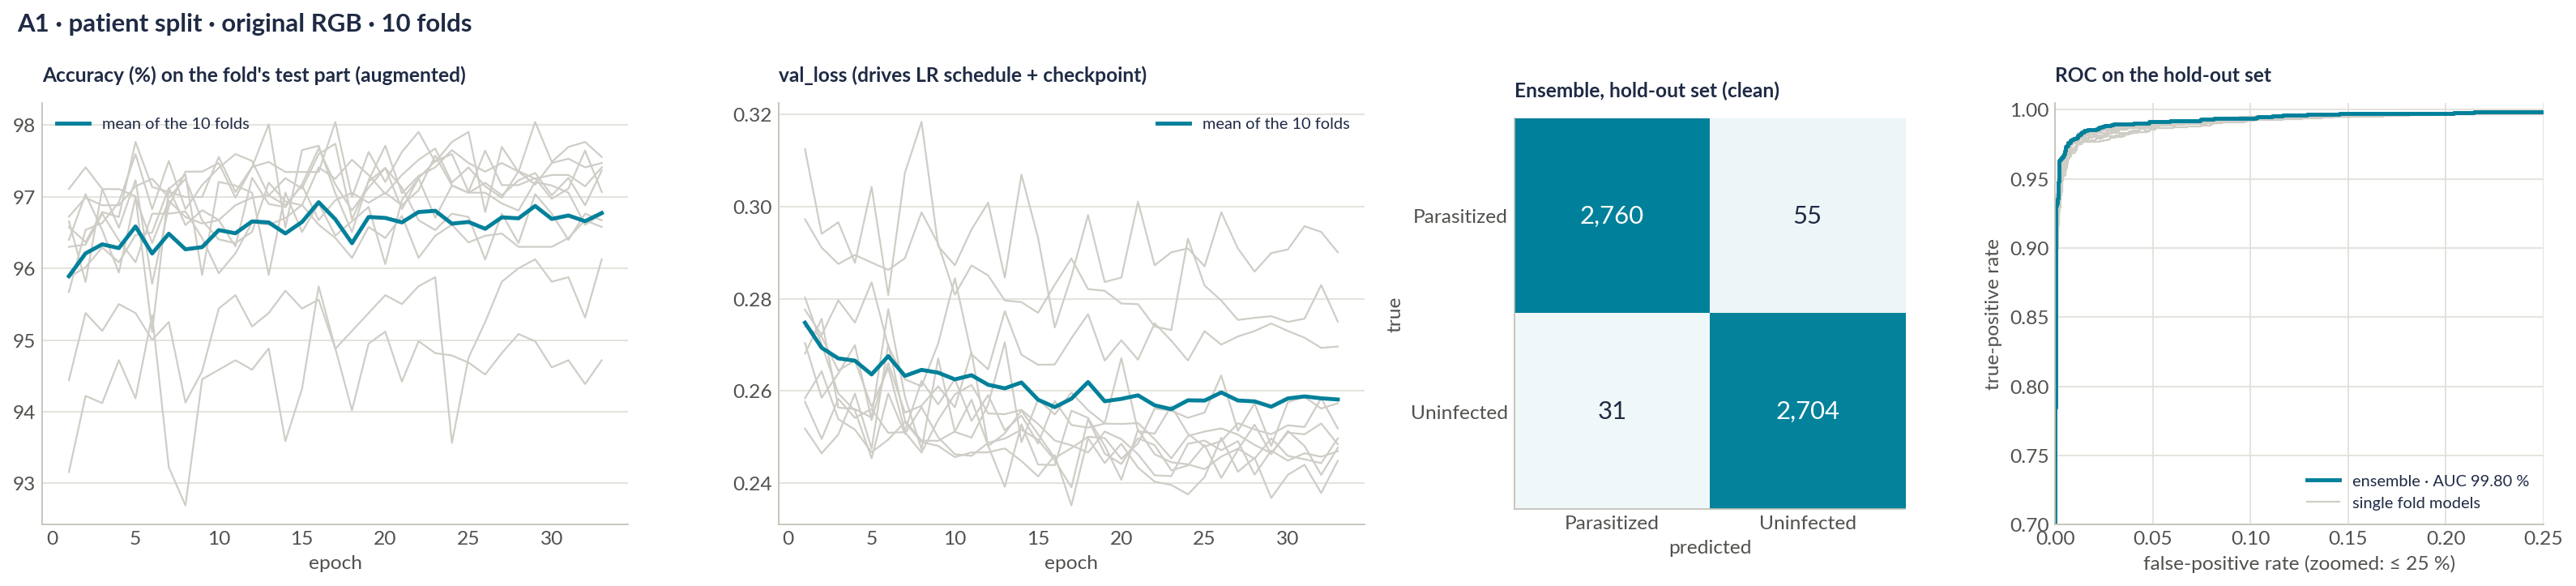

### A2 · H2: does YUV stain normalisation help on unseen patients (A2 vs A1)?

,best epoch,minutes,accuracy,recall,specificity,MCC,ROC-AUC,hold-out acc.,hold-out MCC
0,14.00,10.20,96.61,95.93,97.97,92.59,99.10,98.00,96.00
1,26.00,10.90,97.89,95.15,99.06,94.94,99.19,98.18,96.36
2,23.00,10.40,96.78,97.62,95.27,93.00,99.20,97.89,95.78
3,21.00,10.40,97.31,96.02,98.56,94.65,99.59,98.14,96.29
4,15.00,10.90,97.67,96.69,98.37,95.21,99.33,97.87,95.75
5,30.00,11.40,96.91,96.12,97.49,93.67,99.20,97.62,95.25
6,11.00,10.70,95.45,94.38,97.34,90.45,99.14,98.16,96.32
7,23.00,17.60,97.42,95.52,97.99,92.85,99.42,98.05,96.11
8,22.00,12.80,97.40,97.86,97.00,94.80,99.64,97.77,95.53
9,22.00,15.20,96.13,93.27,97.45,91.01,98.66,98.20,96.40


A2 · 10-model ensemble on the 5,550-cell hold-out set (40 patients), clean protocol · accuracy 98.32 %
              precision    recall  f1-score   support

 Parasitized     0.9847    0.9822    0.9835      2815
  Uninfected     0.9818    0.9843    0.9830      2735

    accuracy                         0.9832      5550
   macro avg     0.9832    0.9833    0.9832      5550
weighted avg     0.9832    0.9832    0.9832      5550

A2 · 10-model ensemble on the 5,550-cell hold-out set (40 patients), paper protocol · accuracy 98.31 %
              precision    recall  f1-score   support

 Parasitized     0.9850    0.9815    0.9833      2815
  Uninfected     0.9811    0.9846    0.9828      2735

    accuracy                         0.9831      5550
   macro avg     0.9830    0.9831    0.9831      5550
weighted avg     0.9831    0.9831    0.9831      5550



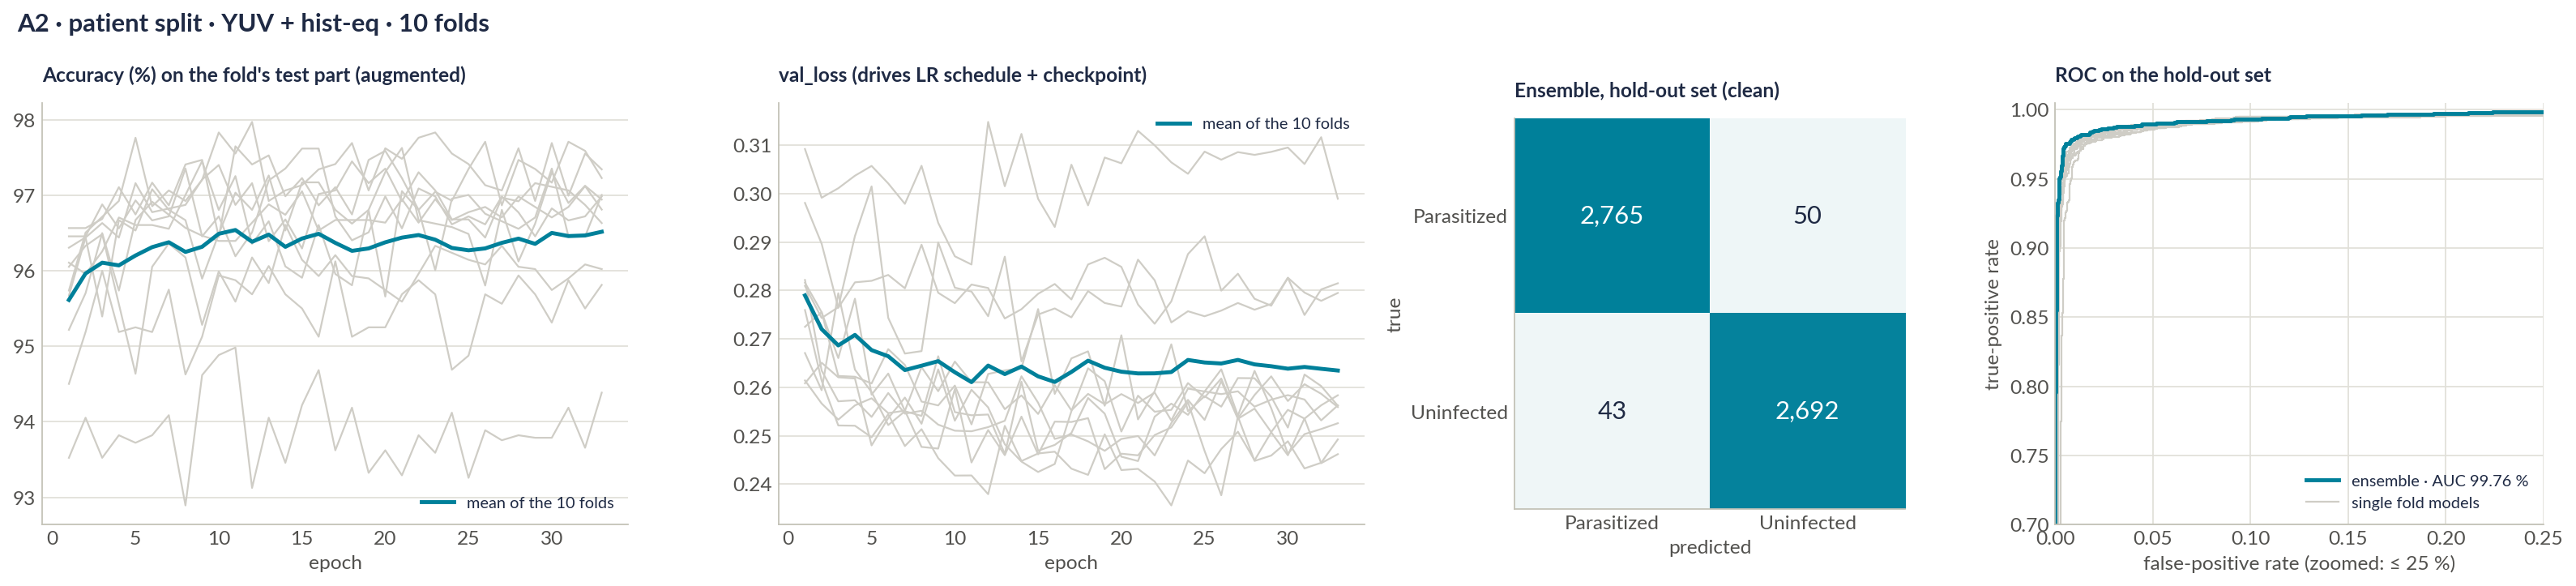

### A3 · Control: does YUV change anything when patients are shared (A3 vs A0)?

,best epoch,minutes,accuracy,recall,specificity,MCC,ROC-AUC,hold-out acc.,hold-out MCC
0,23.00,10.40,97.73,97.38,98.09,95.47,99.57,97.39,94.77
1,32.00,10.80,97.87,97.01,98.73,95.75,99.49,97.46,94.93
2,20.00,10.50,97.32,96.74,97.91,94.66,99.66,97.55,95.11
3,25.00,10.70,97.60,97.74,97.45,95.19,99.10,97.35,94.70
4,30.00,10.70,97.23,96.47,98.00,94.48,99.31,97.37,94.74
5,31.00,11.30,97.60,97.10,98.09,95.20,99.60,97.57,95.14
6,26.00,11.00,97.69,97.55,97.82,95.37,99.66,97.17,94.34
7,33.00,17.80,97.64,96.83,98.45,95.29,99.46,97.35,94.71
8,20.00,12.60,97.64,97.56,97.73,95.28,99.60,97.08,94.17
9,30.00,15.00,97.64,97.83,97.45,95.28,99.51,97.51,95.03


A3 · 10-model ensemble on the 5,512-cell hold-out set (200 patients), clean protocol · accuracy 97.64 %
              precision    recall  f1-score   support

 Parasitized     0.9808    0.9714    0.9761      2730
  Uninfected     0.9722    0.9813    0.9767      2782

    accuracy                         0.9764      5512
   macro avg     0.9765    0.9764    0.9764      5512
weighted avg     0.9765    0.9764    0.9764      5512

A3 · 10-model ensemble on the 5,512-cell hold-out set (200 patients), paper protocol · accuracy 97.66 %
              precision    recall  f1-score   support

 Parasitized     0.9815    0.9711    0.9762      2730
  Uninfected     0.9719    0.9820    0.9769      2782

    accuracy                         0.9766      5512
   macro avg     0.9767    0.9765    0.9766      5512
weighted avg     0.9766    0.9766    0.9766      5512



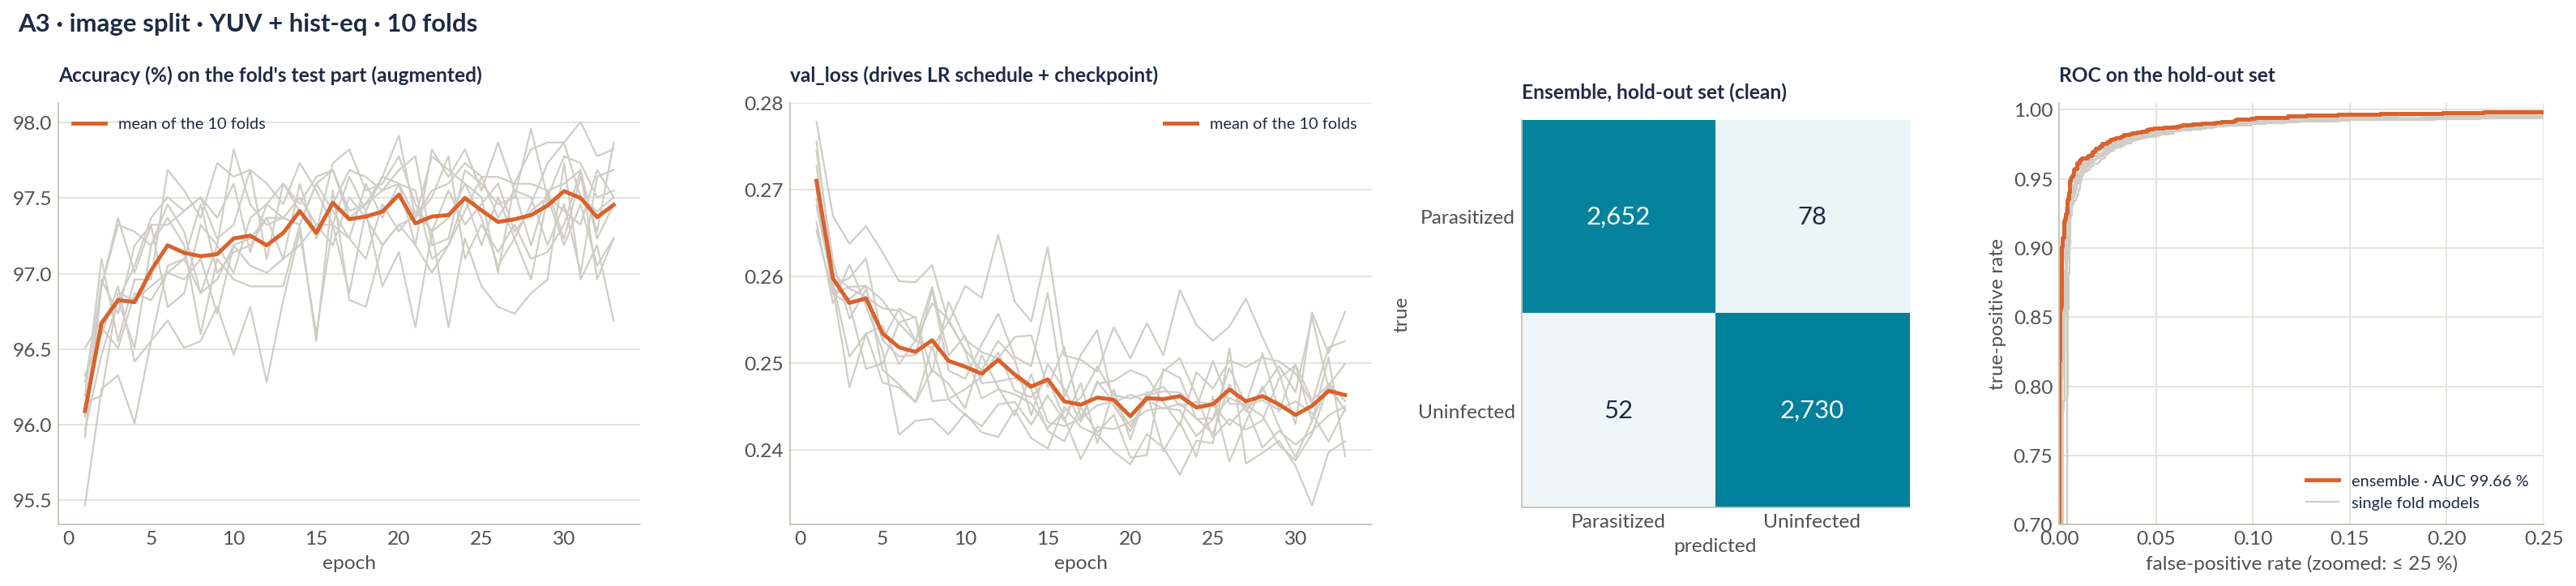

In [8]:
if aggs:
    import ablation_figures as figs  # only needed for the tables, not for training on a pod
for exp, (agg, summary) in aggs.items():
    display(Markdown(f"### {exp} · {mx.EXPERIMENTS[exp]['question']}"))
    pf = agg["per_fold"]["clean"].set_index("fold")
    cols = {"best_epoch": "best epoch", "minutes": "minutes", "cv_accuracy": "accuracy", "cv_recall": "recall",
            "cv_specificity": "specificity", "cv_mcc": "MCC", "cv_auc": "ROC-AUC", "holdout_accuracy": "hold-out acc.",
            "holdout_mcc": "hold-out MCC"}
    t = pf[list(cols)].rename(columns=cols)
    t = pd.concat([t, t.mean().to_frame("mean").T, t.std(ddof=1).to_frame("SD").T])
    display(t.round(2))
    for proto in ["clean", "paper"]:
        pred = agg["ens_probs"][proto].argmax(1)
        print(f"{exp} · 10-model ensemble on the {len(pred):,}-cell hold-out set ({summary['n_patients_holdout']} patients),"
              f" {proto} protocol · accuracy {100 * np.mean(pred == agg['val_true']):.2f} %")
        print(classification_report(agg["val_true"], pred, target_names=mx.TIPOS, digits=4))
    display(Image(figs.experiment_panels(agg, exp, os.path.join(folder(exp), f"{mx.EXPERIMENTS[exp]['prefix']}_curves_cm_roc.png"))))

## 6 · Hypothesis tests: A0 vs A1 vs A2 vs A3
`src/ablation_stats.py`, run on the saved predictions of all four experiments (A0's from Phase 2):
* **Paired contrasts** (A2 vs A1, A3 vs A0: the same cells in both arms): Nadeau–Bengio corrected resampled t-test on the 10 per-fold differences (the folds' training sets overlap by ~89 %, so a plain paired t-test would be too optimistic), and a paired patient bootstrap (resampling whole patients) of the ensemble's hold-out difference.
* **A1 vs A0** (different hold-out sets): independent patient bootstraps per arm for the ensembles. The folds are compared with a Welch-type t-test whose per-arm variance carries the same Nadeau–Bengio correction, because each arm's folds also share their training data. *Correction, 2 Nov 2026:* the plan's plain Welch test treated the folds as independent (p = 0.0075, Holm 0.023) and overstated the evidence; see `docs/phase3b_addendum.md`.
* **Holm** correction over the three contrasts, per metric. Next to the tests: the deck's pre-registered rules.

Written to `results/ablation/` (clean protocol, primary) and `results/ablation/paper_protocol/`.

# Ablation A0–A3: results and hypothesis tests

Primary protocol: **clean** evaluation. Intervals: 95 % patient-cluster bootstrap (10,000 resamples). Metrics in %; MCC × 100.

## Experiments

| ID | Split | Preproc. | Hold-out cells / patients | Fold MCC (mean ± SD) | Fold acc. (mean ± SD) | Ens. acc. [95 % CI] | Ens. MCC [95 % CI] | Ens. recall [95 % CI] | Ens. AUC | Missed / flagged | ECE |
|---|---|---|---|---|---|---|---|---|---|---|---|
| A0 | image | none | 5,512 / 200 | 95.57 ± 0.60 | 97.78 ± 0.30 | 97.64 [97.02, 98.17] | 95.29 [94.03, 96.32] | 97.18 [96.03, 98.06] | 99.68 | 77 / 53 | 0.053 |
| A1 | patient | none | 5,550 / 40 | 93.92 ± 1.51 | 97.24 ± 0.66 | 98.45 [97.94, 98.91] | 96.90 [95.70, 97.79] | 98.05 [96.79, 98.85] | 99.80 | 55 / 31 | 0.065 |
| A2 | patient | yuv | 5,550 / 40 | 93.32 ± 1.66 | 96.96 ± 0.75 | 98.32 [97.71, 98.86] | 96.65 [95.23, 97.68] | 98.22 [97.02, 99.02] | 99.76 | 50 / 43 | 0.060 |
| A3 | image | yuv | 5,512 / 200 | 95.20 ± 0.37 | 97.60 ± 0.19 | 97.64 [97.02, 98.17] | 95.29 [94.04, 96.32] | 97.14 [95.94, 98.05] | 99.66 | 78 / 52 | 0.052 |

## Contrasts (difference = new − reference, in pp)

Fold level: Nadeau–Bengio corrected resampled t-test when the folds are paired; when they are not (A1 vs A0), a Welch-type t-test whose per-arm variance carries the same Nadeau–Bengio correction, because each arm's folds share their training data. Ensemble level: patient bootstrap. Holm correction over the three contrasts, per metric.

### A1 vs A0: H1: patient-level split vs the paper's image split (leakage)

| Metric | Fold Δ | Fold p | Fold p (Holm) | Ensemble Δ [95 % CI] | Ensemble p | Ensemble p (Holm) |
|---|---|---|---|---|---|---|
| mcc | -1.65 | 0.0472 | 0.142 | +1.62 [+0.01, +3.12] | 0.0488 | 0.146 |
| accuracy | -0.54 | 0.131 | 0.364 | +0.81 [+0.06, +1.57] | 0.034 | 0.102 |
| recall | -1.27 | 0.0798 | 0.24 | +0.87 [-0.67, +2.25] | 0.249 | 0.748 |
| specificity | -0.26 | 0.509 | 0.687 | +0.77 [+0.00, +1.53] | 0.0484 | 0.118 |
| balanced_accuracy | -0.77 | 0.0473 | 0.142 | +0.82 [-0.04, +1.59] | 0.0594 | 0.178 |
| f2 | -1.20 | 0.0778 | 0.233 | +0.86 [-0.52, +2.02] | 0.19 | 0.571 |
| auc | -0.23 | 0.136 | 0.18 | +0.12 [-0.10, +0.32] | 0.288 | 0.593 |

First-reported fold p without the correction (plain Welch, folds treated as independent): MCC 0.00752, accuracy 0.0358. It overstated the evidence; see docs/phase3b_addendum.md.

### A2 vs A1: H2: YUV stain normalisation on unseen patients

| Metric | Fold Δ | Fold p | Fold p (Holm) | Ensemble Δ [95 % CI] | Ensemble p | Ensemble p (Holm) |
|---|---|---|---|---|---|---|
| mcc | -0.60 | 0.132 | 0.246 | -0.26 [-0.85, +0.23] | 0.319 | 0.637 |
| accuracy | -0.28 | 0.137 | 0.364 | -0.13 [-0.41, +0.11] | 0.378 | 0.756 |
| recall | -0.20 | 0.304 | 0.609 | +0.18 [-0.11, +0.53] | 0.255 | 0.748 |
| specificity | -0.33 | 0.229 | 0.687 | -0.44 [-0.92, -0.04] | 0.0392 | 0.118 |
| balanced_accuracy | -0.26 | 0.149 | 0.243 | -0.13 [-0.41, +0.14] | 0.358 | 0.716 |
| f2 | -0.23 | 0.171 | 0.342 | +0.06 [-0.20, +0.33] | 0.609 | 1 |
| auc | -0.18 | 0.075 | 0.18 | -0.04 [-0.09, +0.02] | 0.198 | 0.593 |

### A3 vs A0: Control: YUV stain normalisation when patients are shared

| Metric | Fold Δ | Fold p | Fold p (Holm) | Ensemble Δ [95 % CI] | Ensemble p | Ensemble p (Holm) |
|---|---|---|---|---|---|---|
| mcc | -0.37 | 0.123 | 0.246 | +0.00 [-0.52, +0.53] | 1 | 1 |
| accuracy | -0.19 | 0.121 | 0.364 | +0.00 [-0.26, +0.27] | 1 | 1 |
| recall | -0.10 | 0.513 | 0.609 | -0.04 [-0.43, +0.33] | 0.935 | 0.935 |
| specificity | -0.27 | 0.313 | 0.687 | +0.04 [-0.36, +0.43] | 0.917 | 0.917 |
| balanced_accuracy | -0.19 | 0.122 | 0.243 | -0.00 [-0.27, +0.27] | 0.999 | 0.999 |
| f2 | -0.13 | 0.219 | 0.342 | -0.02 [-0.35, +0.28] | 0.889 | 1 |
| auc | -0.16 | 0.0599 | 0.18 | -0.02 [-0.11, +0.05] | 0.663 | 0.663 |

## Verdicts

- **H1 (leakage)**: ensemble MCC 95.29 → 96.90 (Δ +1.62 pp, 95 % CI +0.01 to +3.12, Holm p = 0.146); accuracy Δ +0.81 pp. Fold SD of accuracy 0.30 → 0.66 pp. Cross-validation: fold MCC Δ -1.65 pp (95 % CI -3.28 to -0.02, corrected p = 0.0472, Holm p = 0.142). **Not supported** at the 5 % level: the patient-level split does not score clearly lower.
- **H2 (YUV on unseen patients)**: mean fold MCC gain -0.60 pp vs A1's fold SD 1.51 pp → pre-registered rule: **reject H2**. Ensemble MCC Δ -0.26 pp (95 % CI -0.85 to +0.23, Holm p = 0.637); recall Δ +0.18 pp; fold t-test p = 0.132. H2 is not supported.
- **Control (YUV, shared patients)**: mean fold MCC Δ -0.37 pp (A0 fold SD 0.60 pp); ensemble MCC Δ +0.00 pp (95 % CI -0.52 to +0.53). As expected, YUV changes little when patients are shared.

## Extras on the same predictions

| ID | CV-chosen threshold (max F2) | Hold-out recall at it | Specificity at it |
|---|---|---|---|
| A0 | 0.192 | 98.72 | 95.22 |
| A1 | 0.189 | 99.22 | 93.93 |
| A2 | 0.143 | 99.22 | 91.74 |
| A3 | 0.159 | 98.75 | 94.14 |


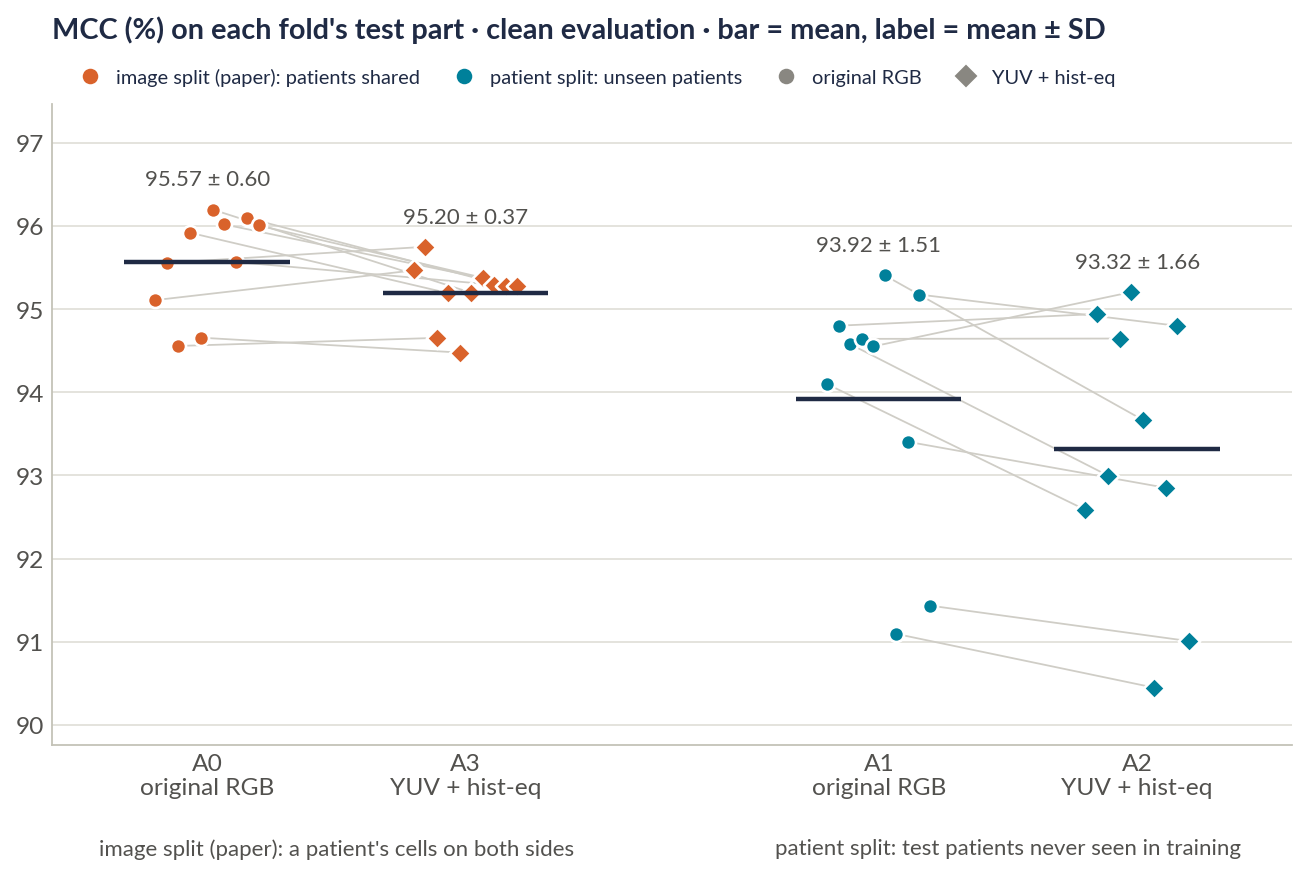

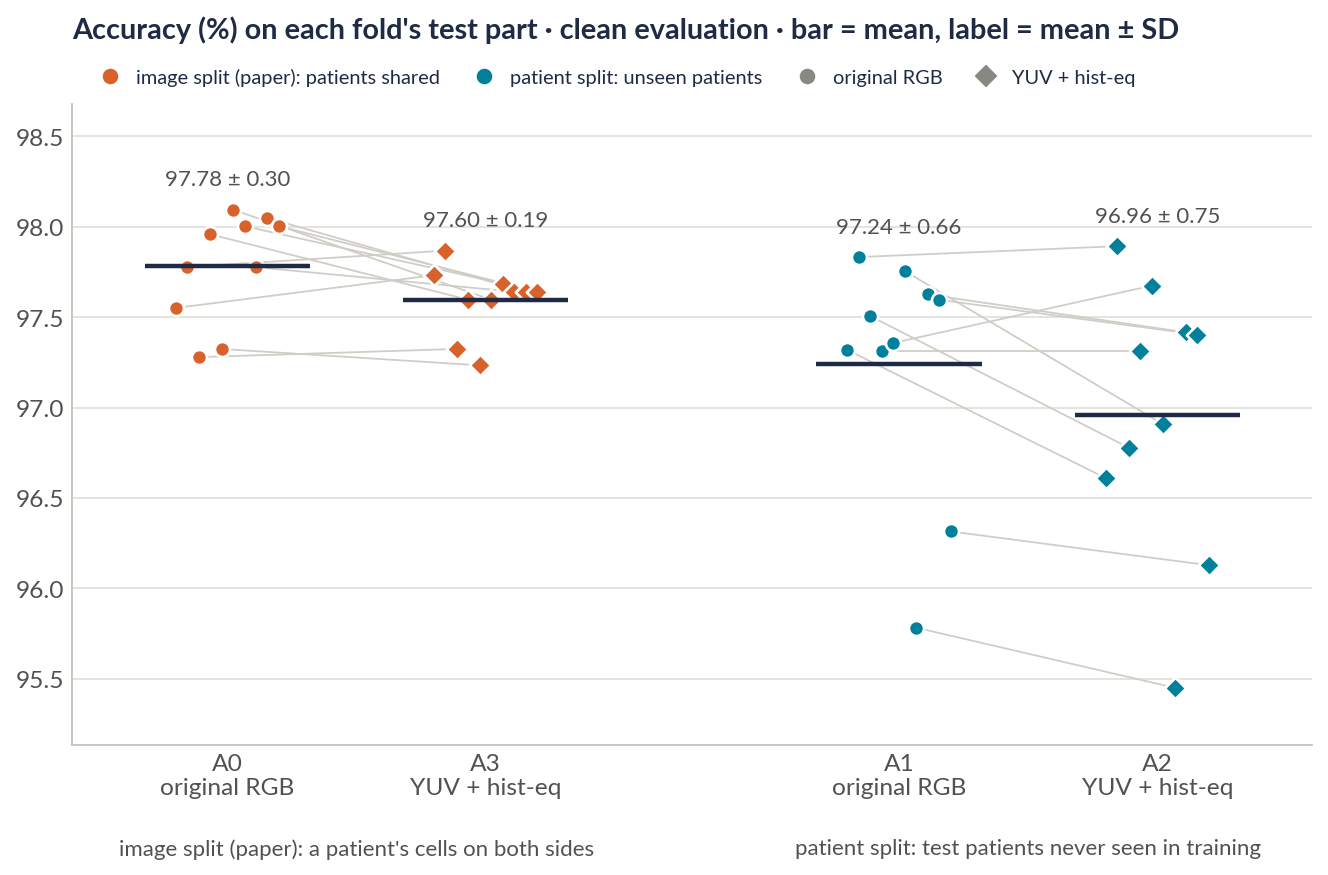

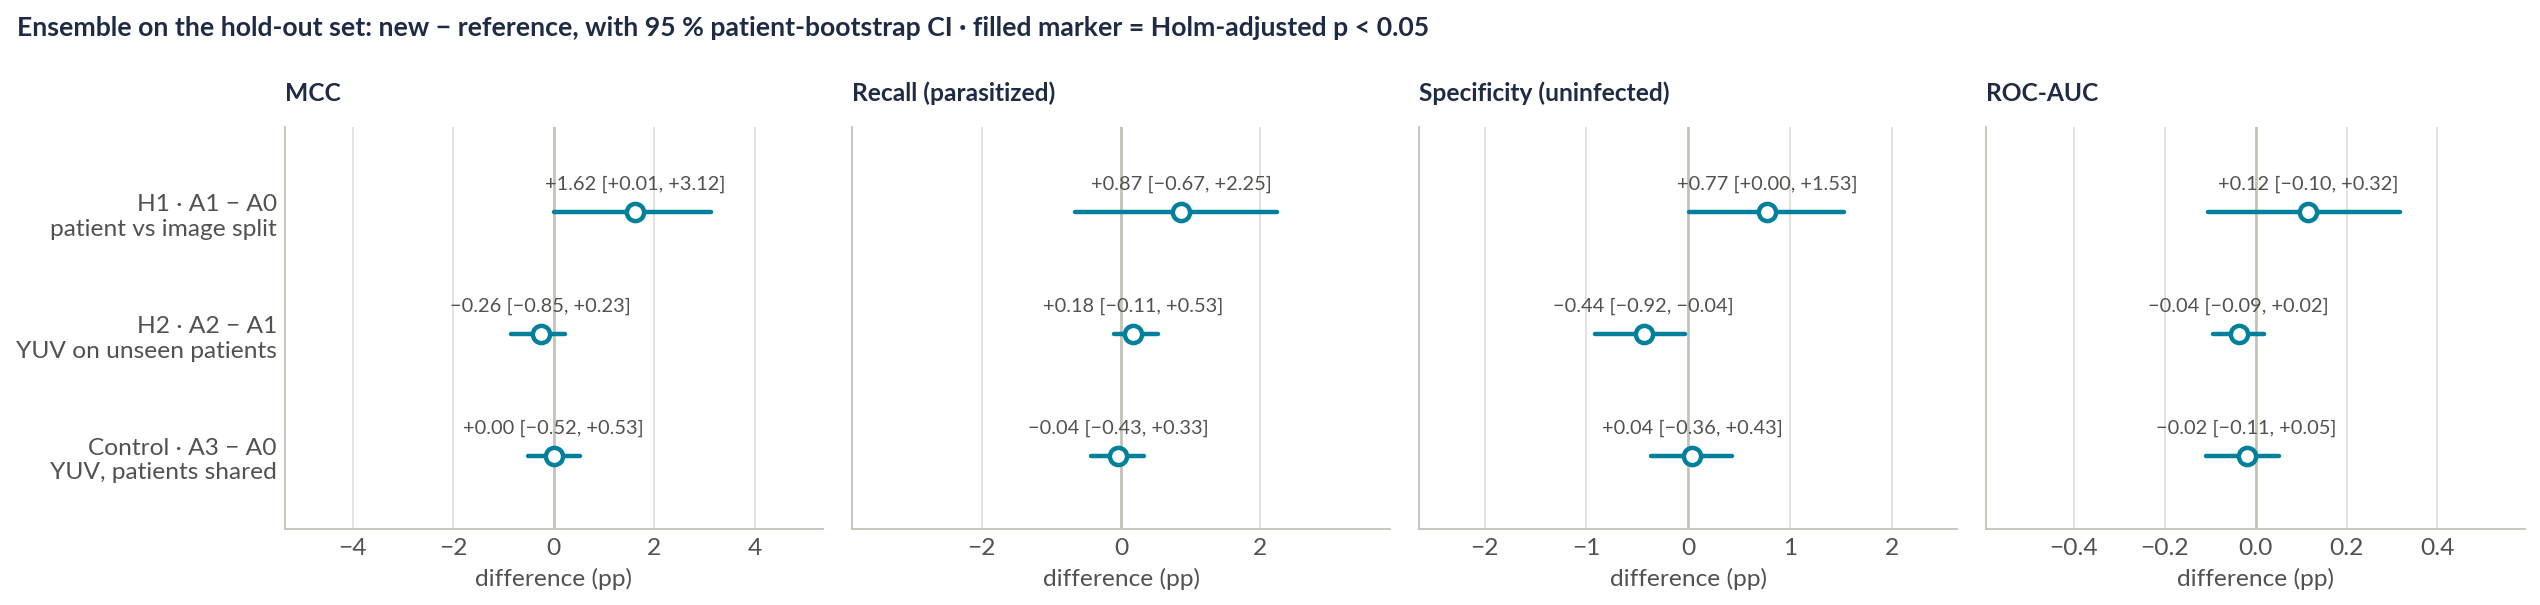

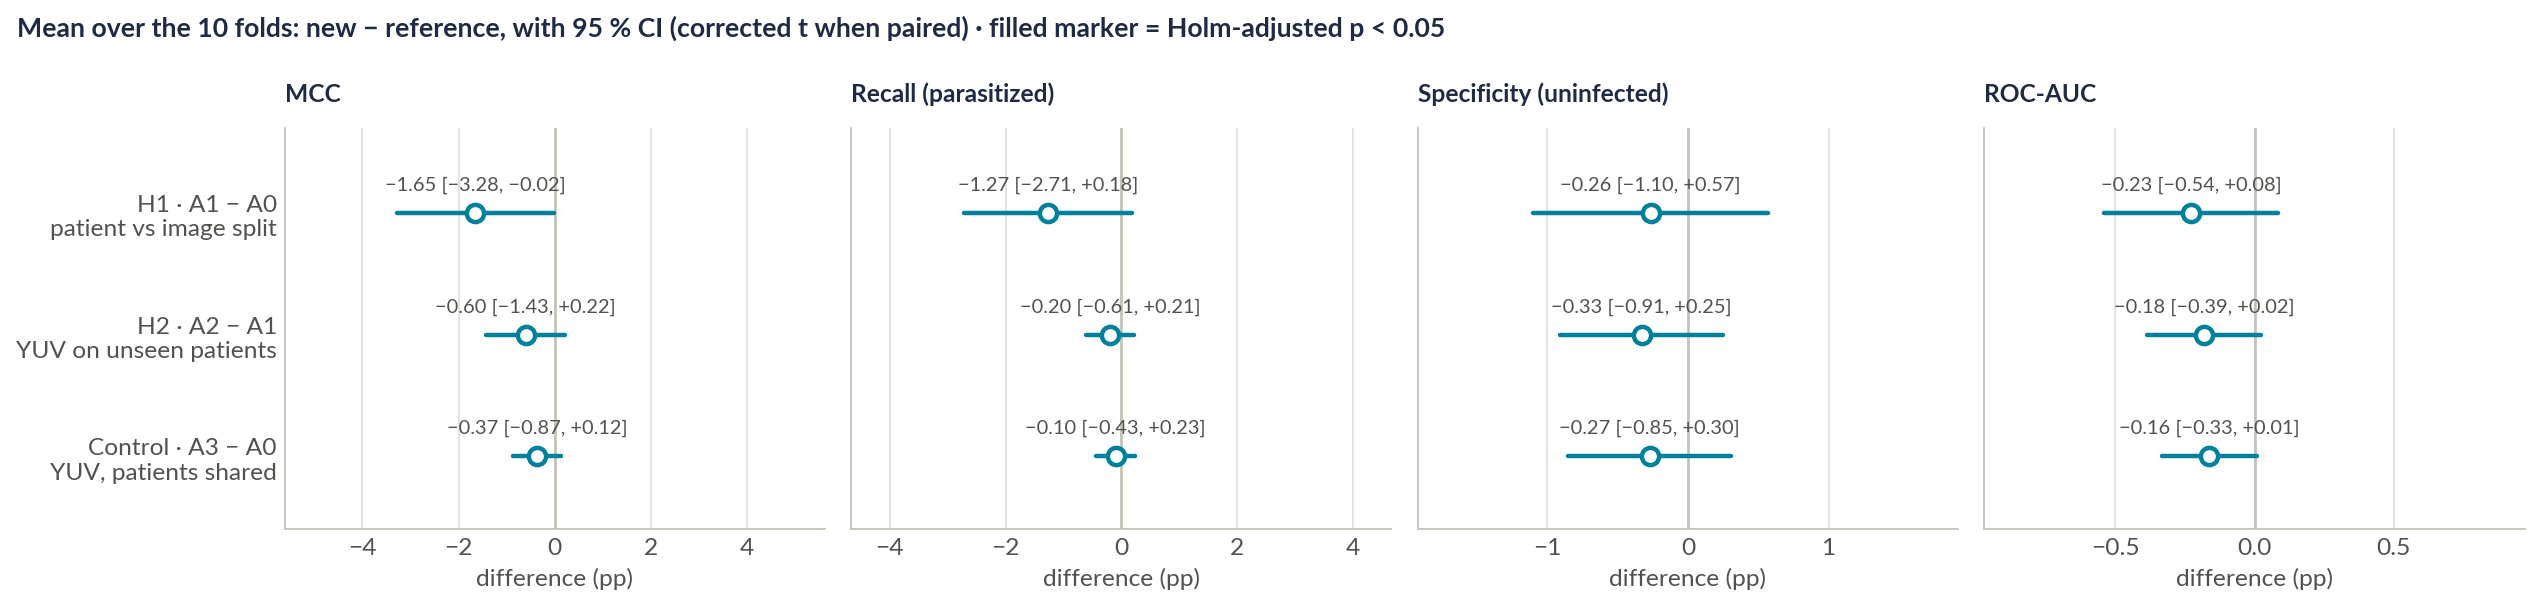

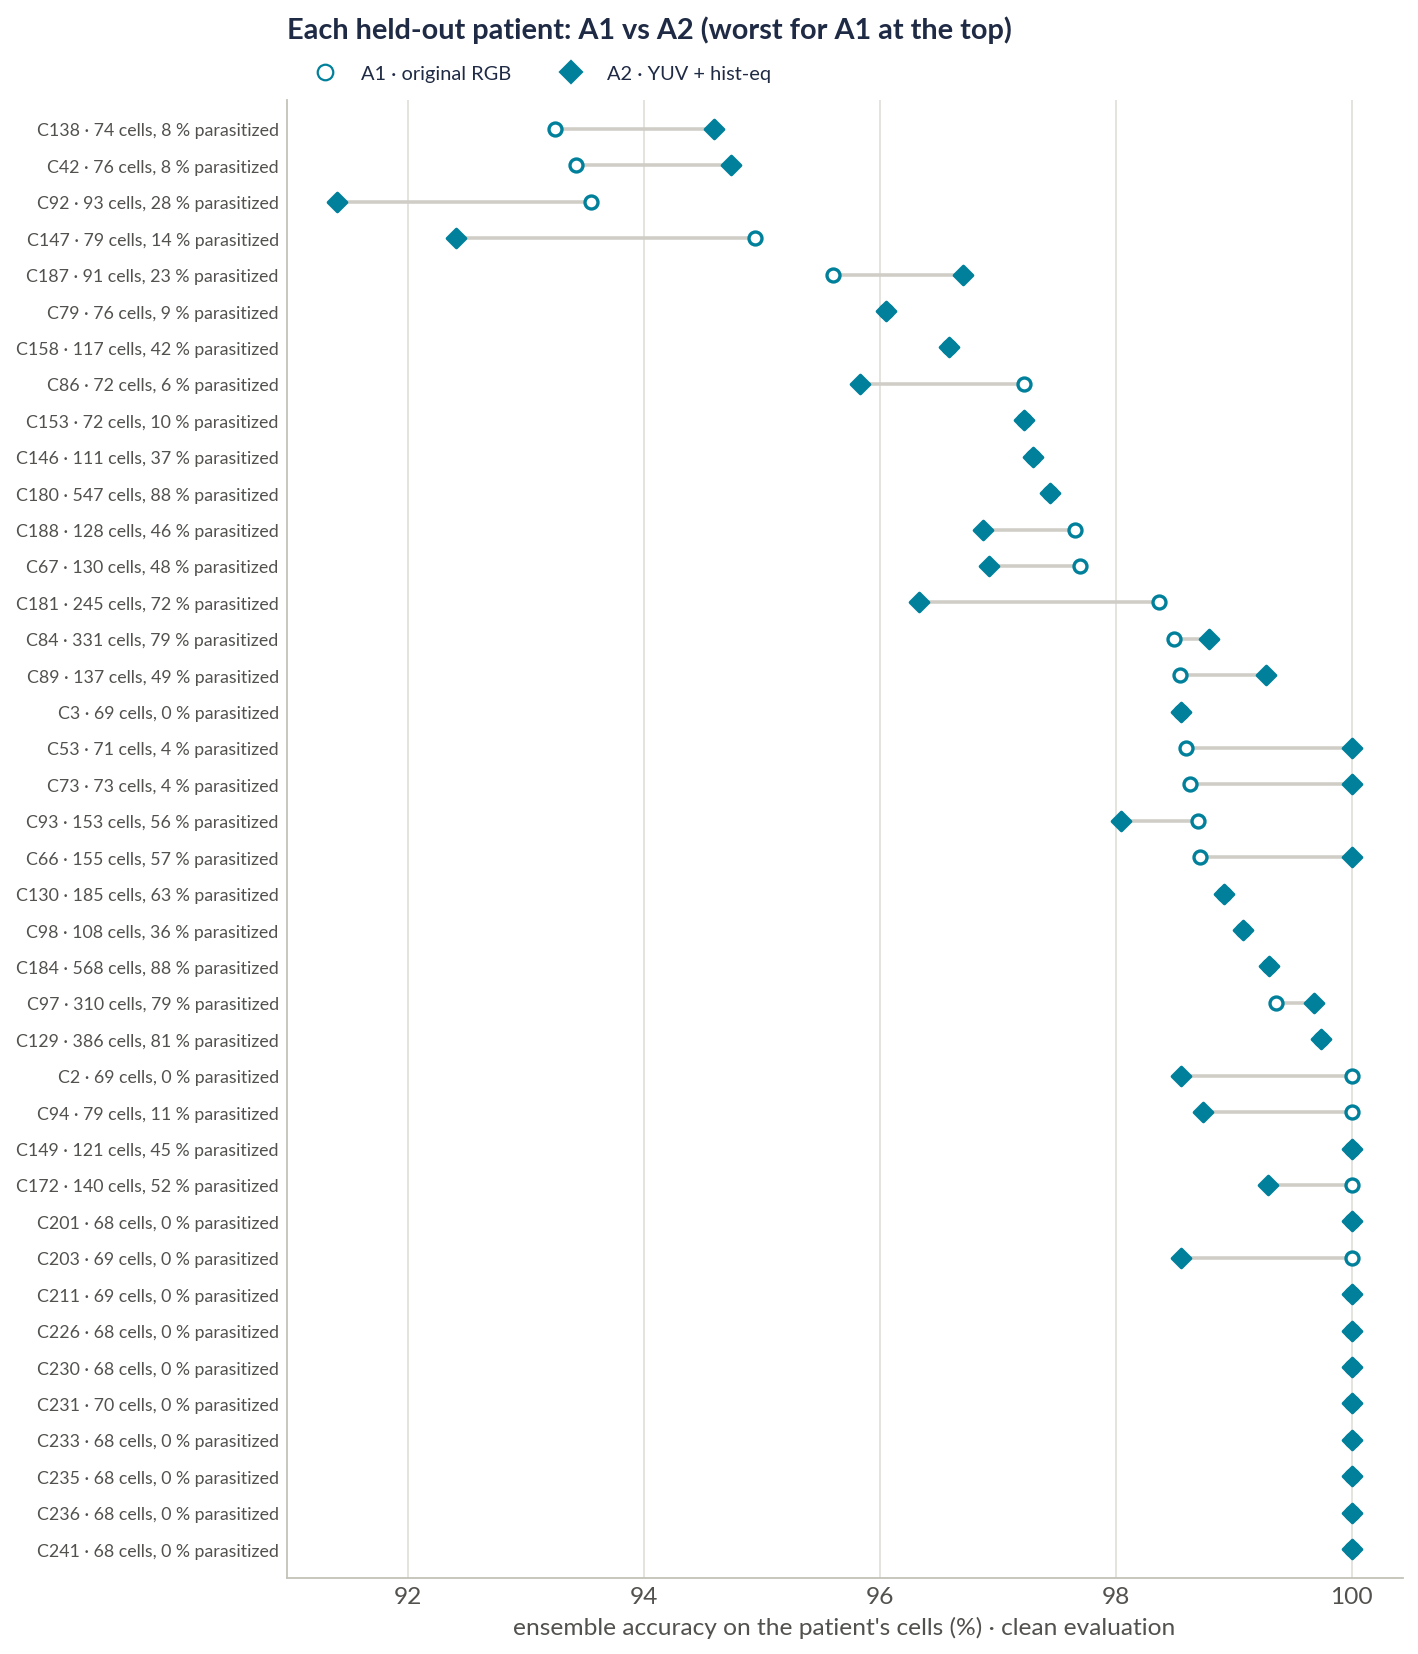

In [9]:
if not TRAINING and not SMOKE:
    import ablation_figures as figs
    import ablation_stats as st
    out = st.analyse(RESULTS_ROOT, n_boot=N_BOOT)
    st.analyse(RESULTS_ROOT, out_dir=os.path.join(RESULTS_ROOT, "ablation", "paper_protocol"), n_boot=N_BOOT, protocol="paper")
    display(Markdown(out["text"]))
    abl = os.path.join(RESULTS_ROOT, "ablation")
    if len(out["found"]) > 1:
        display(Image(figs.fold_strip(out["found"], "mcc", path=os.path.join(abl, "ablation_fold_mcc.png"))))
        display(Image(figs.fold_strip(out["found"], "accuracy", path=os.path.join(abl, "ablation_fold_accuracy.png"))))
    if out["contrasts"]:
        display(Image(figs.contrast_forest(out["contrasts"], path=os.path.join(abl, "ablation_contrasts.png"))))
        display(Image(figs.contrast_forest(out["contrasts"], level="fold", path=os.path.join(abl, "ablation_contrasts_folds.png"))))
    if {"A1", "A2"} <= set(out["found"]):
        display(Image(figs.per_patient(out["found"], "A1", "A2", path=os.path.join(abl, "ablation_per_patient.png"))))

## 7 · Limitations (stated before the results)
* **Cells, not patients.** The task is still single-cell classification; three quarters of the uninfected cells come from infected patients' smears. A patient-level diagnosis would need slide-level aggregation and is not tested here.
* **One hold-out split per hypothesis.** The patient hold-out has 40 patients; which 40 matters. The 10-fold CV spread and the patient bootstrap show how much that uncertainty is, but a different hold-out draw would move the numbers.
* **Labels from one expert.** Fuhad *et al.* (2020) set aside 1,397 cells (5.1 %) as mislabelled or suspicious after consulting one expert; their list is no longer online. All results use the original labels, as the paper did.
* **Same hospital, shared imaging days.** A patient split removes patient leakage, not site or day effects; there is no external test set, so H2 is tested on unseen patients of the same lab, not on another lab's stain.
* **Run-to-run noise.** Each arm is one training run per fold; the corrected t-test uses the spread across folds, which includes training noise, but the ensemble bootstrap does not.
* **Hardware.** A0 trained on RTX 4090s. A1–A3 ran on 7 RTX 4090s and 3 L40S (folds 5, 7, 9; Secure Cloud stock was low). Within a fold, A1, A2 and A3 shared one GPU, so the paired comparisons are on identical hardware.

## 8 · Conclusion
* **The paper's ~98 % survives unseen patients.** On the 40 held-out patients the A1 ensemble reaches **98.45 %** accuracy (95 % patient-bootstrap CI 97.94–98.91) and MCC 96.90, no lower than A0's 97.64 % on its image-split hold-out set. By the pre-registered rule, **H1 is not supported.**
* **The leakage is small and statistically fragile.** Cross-validation over the other 160 patients is a broader test than one 40-patient hold-out set. It points the way H1 predicted, at a small size: mean fold MCC 93.92 vs 95.57, a point estimate of −1.65 pp (95 % CI −3.28 to −0.02 after correcting for the folds' shared training data; p = 0.047, Holm p = 0.14). Fold accuracy is 97.24 vs 97.78 % (−0.54 pp, CI −1.27 to +0.18), with 2.5× the fold-to-fold spread (MCC SD 1.51 vs 0.60). An uncorrected Welch test first gave p = 0.0075 (Holm 0.023); it treated the ten folds as independent. The same A1 models score 98.22 % on the 40 held-out patients but 97.24 % in cross-validation. So this particular hold-out draw is about 1 pp easier than an average group of unseen patients, more than the leakage effect itself. With unseen-patient validation the best epoch also comes earlier (median 17 vs 28.5).
* **YUV luma equalisation does not help on unseen patients from the same hospital: H2 is rejected.** On the same unseen patients, A2 vs A1 changes mean fold MCC by −0.60 pp (95 % CI −1.43 to +0.22). That is smaller than A1's fold SD of 1.51 pp, so the pre-registered rule rejects H2; the corrected t-test gives p = 0.13. The ensemble MCC changes by −0.26 pp (95 % CI −0.85 to +0.23), and specificity drops slightly (−0.44 pp, not significant after Holm). The step equalises brightness only (the Y channel), not stain colour, and the training pipeline already randomises brightness and contrast. The control A3 vs A0 shows no detectable change when patients are shared (ensemble MCC +0.00 pp, 95 % CI −0.52 to +0.53).
* **Both conclusions hold under the paper's augmented protocol** (`results/ablation/paper_protocol/`).
* **For screening:** a threshold chosen on the CV folds raises hold-out recall to 98.7–99.2 %, at 91.7–95.2 % specificity. The ensembles are slightly under-confident (ECE 0.05–0.07), as label smoothing predicts.
* **Compute:** 30 models on 10 RunPod pods (7× RTX 4090, 3× L40S) in about one hour, for $6.95.